In [1]:
import matplotlib.pyplot as plt
import model.model_builder as model_builder
import numpy as np
import utils.param_loader as param_loader
import utils.unit_conversion as uc

In [2]:
def run_one_param(model, param, range, step_no):
    results = []

    for value in np.linspace(range[0], range[1], step_no):
        model.set_parameter_value(param, value)
        result = model.run()
        results.append(result)

    return results

In [3]:
params = param_loader.load_parameters()

model = model_builder.ModelBuilder(params)
model.build()

In [4]:
model.build()
v_pmax = run_one_param(model, 'v_pmax', (0.1, 200), 100)
model.build()
v_cmax_mes = run_one_param(model, 'v_cmax_mes', (0.1, 200), 100)
model.build()
v_cmax_bs = run_one_param(model, 'v_cmax_bs', (0.1, 200), 100)
model.build()
k_c = run_one_param(model, 'k_c', (uc.ubar_to_molar_concentration(300), uc.ubar_to_molar_concentration(2400)), 100)
model.build()
k_o = run_one_param(model, 'k_o', (uc.ubar_to_molar_concentration(210000), uc.ubar_to_molar_concentration(700000)), 100)
model.build()
k_p = run_one_param(model, 'k_p', (uc.ubar_to_molar_concentration(50), uc.ubar_to_molar_concentration(1700)), 100)
model.build()
g_bs = run_one_param(model, 'g_bs', (0.0001, 0.1), 100)
model.build()
leaf_water_potential = run_one_param(model, 'leaf_water_potential', (-3e6, -0.1e6), 100)
model.build()
k_l = run_one_param(model, 'k_l', (0.0001e-6, 0.01e-6), 100)


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



In [5]:
model.build()
f_canopy = run_one_param(model, 'f_canopy', (0.1, 1), 100)
model.build()
u_a = run_one_param(model, 'u_a', (0.1, 70), 100)


In [6]:
model.build()
g_h = run_one_param(model, 'g_h', (0.01, 10), 100)

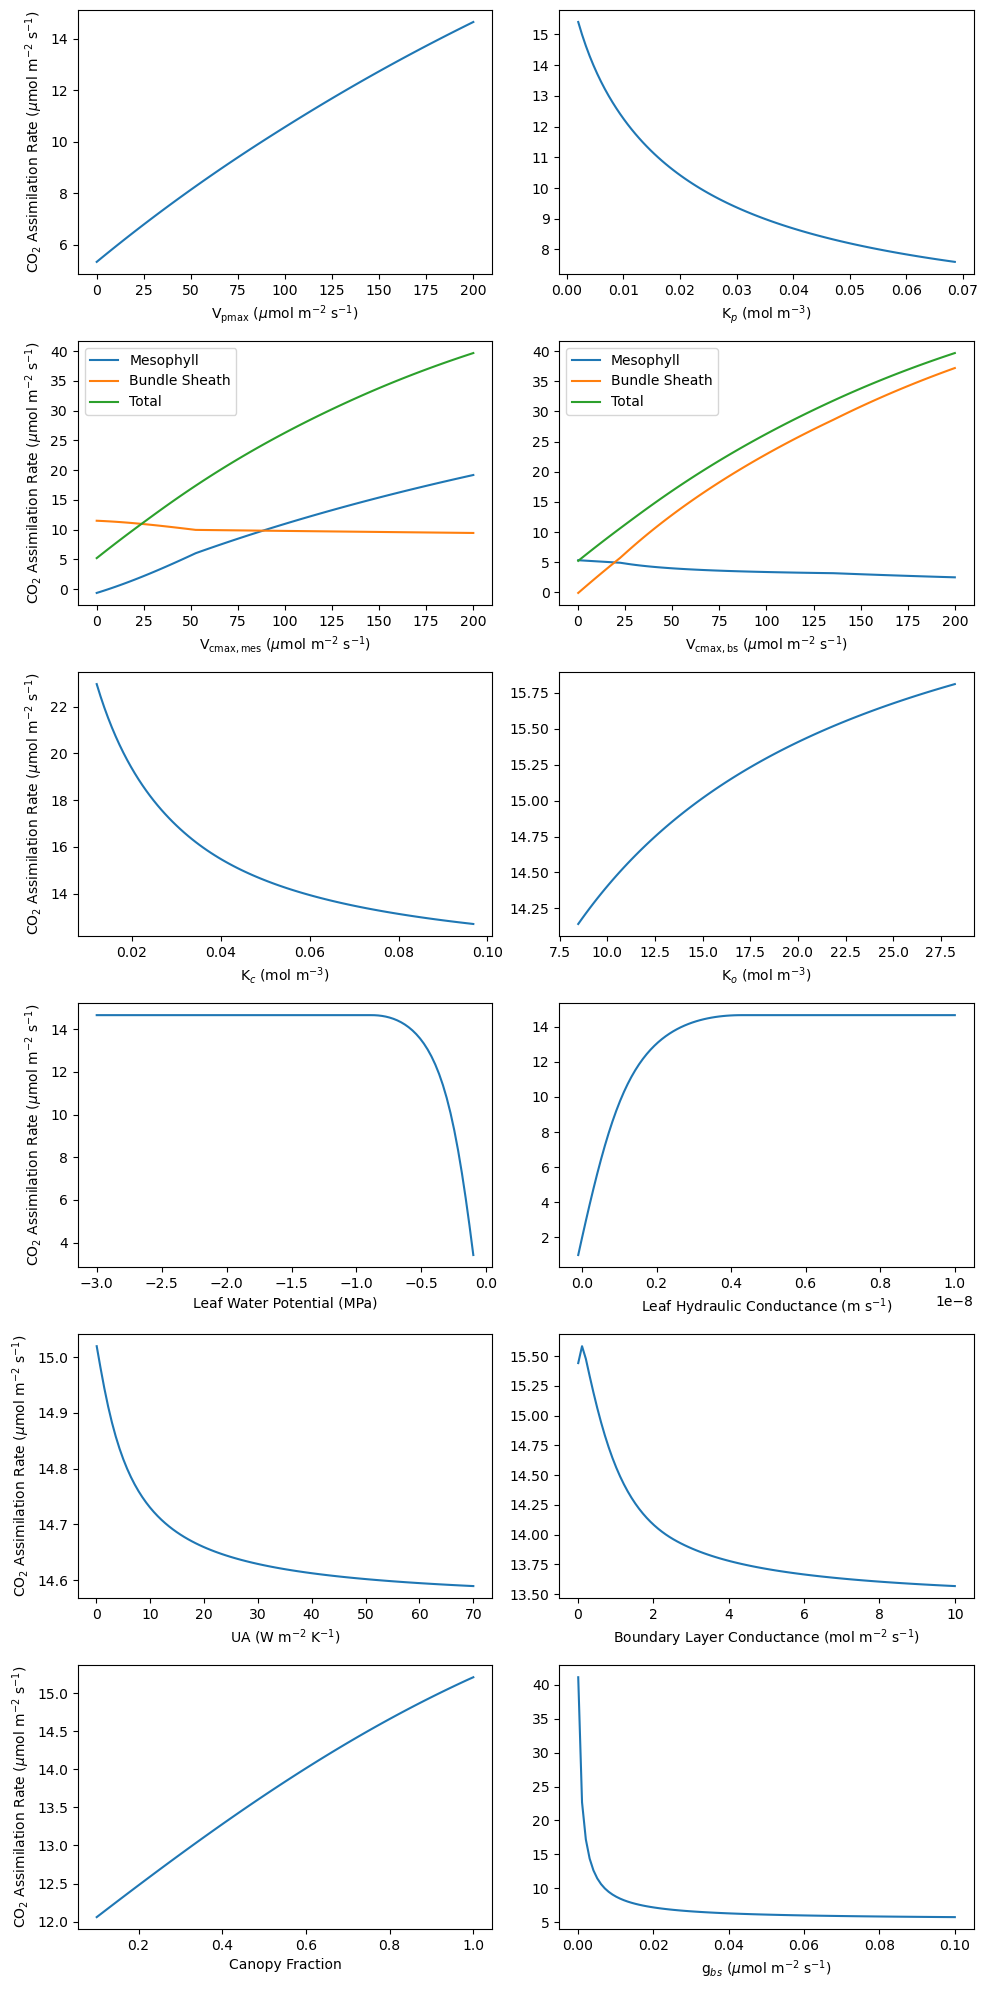

In [7]:
fig, axs = plt.subplots(6, 2, figsize=(10, 20))
axs[0, 0].plot(np.linspace(0.1, 200, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs'])  for value in v_pmax])
axs[0, 0].set_xlabel('V$_{\\rm pmax}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[0, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')

axs[0, 1].plot(np.linspace(uc.ubar_to_molar_concentration(50)/1e6, uc.ubar_to_molar_concentration(1700)/1e6, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in k_p])
axs[0, 1].set_xlabel('K$_p$ (mol m$^{-3}$)')

axs[1, 0].plot(np.linspace(0.1, 200, 100), [value['co2_assimilation_rate_mes'] for value in v_cmax_mes], label='Mesophyll')
axs[1, 0].plot(np.linspace(0.1, 200, 100), [value['co2_assimilation_rate_bs'] for value in v_cmax_mes], label='Bundle Sheath')
axs[1, 0].plot(np.linspace(0.1, 200, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in v_cmax_bs], label='Total')
axs[1, 0].set_xlabel('V$_{\\rm cmax,mes}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1, 0].legend()

axs[1, 1].plot(np.linspace(0.1, 200, 100), [value['co2_assimilation_rate_mes'] for value in v_cmax_bs], label='Mesophyll')
axs[1, 1].plot(np.linspace(0.1, 200, 100), [value['co2_assimilation_rate_bs'] for value in v_cmax_bs], label='Bundle Sheath')
axs[1, 1].plot(np.linspace(0.1, 200, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in v_cmax_bs], label='Total')
axs[1, 1].set_xlabel('V$_{\\rm cmax,bs}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')
axs[1, 1].legend()

axs[2, 0].plot(np.linspace(uc.ubar_to_molar_concentration(300)/1e6, uc.ubar_to_molar_concentration(2400)/1e6, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in k_c])
axs[2, 0].set_xlabel('K$_c$ (mol m$^{-3}$)')
axs[2, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')

axs[2, 1].plot(np.linspace(uc.ubar_to_molar_concentration(210000)/1e6, uc.ubar_to_molar_concentration(700000)/1e6, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in k_o])
axs[2, 1].set_xlabel('K$_o$ (mol m$^{-3}$)')

axs[3, 0].plot(np.linspace(-3, -0.1, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in leaf_water_potential])
axs[3, 0].set_xlabel('Leaf Water Potential (MPa)')
axs[3, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')

axs[3, 1].plot(np.linspace(-0.0001e-6, 0.01e-6, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in k_l])
axs[3, 1].set_xlabel('Leaf Hydraulic Conductance (m s$^{-1}$)')

axs[4, 0].plot(np.linspace(0.1, 70, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in u_a])
axs[4, 0].set_xlabel('UA (W m$^{−2}$ K$^{-1}$)')
axs[4, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')

axs[4, 1].plot(np.linspace(0.01, 10, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in g_h])
axs[4, 1].set_xlabel('Boundary Layer Conductance (mol m$^{-2}$ s$^{-1}$)')

axs[5, 0].plot(np.linspace(0.1, 1, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in f_canopy])
axs[5, 0].set_xlabel('Canopy Fraction')
axs[5, 0].set_ylabel('CO$_2$ Assimilation Rate ($\\mu$mol m$^{-2}$ s$^{-1}$)')

axs[5, 1].plot(np.linspace(0.0001, 0.1, 100), [(value['co2_assimilation_rate_mes'] + value['co2_assimilation_rate_bs']) for value in g_bs])
axs[5, 1].set_xlabel('g$_{bs}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)')

plt.tight_layout()